In [1]:
import numpy as np
import pandas as pd
from scipy.stats import skew, kurtosis
from sklearn.linear_model import LinearRegression
import time
import matplotlib.pyplot as plt
import seaborn as sns

### First create one point hpi dataframe

In [6]:
def remove_rows_by_countries(df, country_list, column="Country"):
    """
    Removes rows from the DataFrame where the value in the specified column matches any country in the list.
    Prints a message if any country in the list is not found.

    Parameters:
    - df: Original DataFrame.
    - country_list: List of country names to remove.
    - column: Name of the column containing country names (default is 'Country').

    Returns:
    - DataFrame without the rows corresponding to those countries.
    """
    df = df.copy()
    existing_countries = set(df[column].dropna().astype(str).unique())
    not_found = [country for country in country_list if country not in existing_countries]

    if not_found:
        print(f"⚠️ The following countries were not found in column '{column}': {not_found}")

    return df[~df[column].isin(country_list)].copy()

In [7]:
one_point_country = pd.read_parquet('../data/one_point_countries.parquet')

In [8]:
one_point_country

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_cv,labor_force_min,labor_force_max,labor_force_last,labor_force_growth,labor_force_skew,...,govermment_effective__std,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend,iso_a3
0,Australia,13.582,13.585,0.618398,0.045531,12.73,14.50,14.50,0.139042,9.708975e-02,...,0.036180,2.347833e-02,1.47,1.59,1.59,0.039216,-0.346877,-0.627720,0.005273,AUS
1,Austria,4.679,4.650,0.092569,0.019784,4.57,4.83,4.83,0.056893,5.307563e-01,...,0.078968,5.401392e-02,1.33,1.61,1.33,-0.095238,-0.207178,-0.148237,-0.011879,AUT
2,Belgium,5.205,5.180,0.151013,0.029013,5.00,5.42,5.42,0.084000,1.460862e-01,...,0.129016,1.088738e-01,1.04,1.40,1.04,-0.257143,0.542175,-1.048411,-0.037758,BEL
3,Brazil,103.729,103.950,2.291325,0.022090,99.69,106.30,106.10,0.048419,-3.730231e-01,...,0.135632,-3.214025e-01,-0.59,-0.23,-0.55,1.200000,0.321185,-1.620024,-0.038182,BRA
4,Bulgaria,3.255,3.270,0.095525,0.029347,3.09,3.38,3.09,-0.055046,-6.246670e-01,...,0.146969,-5.295130e+16,-0.27,0.17,0.05,-0.444444,-0.794950,-1.012397,-0.022303,BGR
5,Canada,20.814,20.625,0.798476,0.038362,19.88,22.14,22.14,0.113682,5.477548e-01,...,0.099524,6.050083e-02,1.52,1.82,1.52,-0.126437,0.228245,-1.279805,-0.031697,CAN
6,Chile,9.263,9.165,0.433037,0.046749,8.76,9.96,9.96,0.136986,5.162040e-01,...,0.110910,1.472907e-01,0.55,0.91,0.72,-0.132530,-0.487748,-0.865772,-0.025273,CHL
7,Colombia,25.152,25.075,0.851267,0.033845,23.97,26.29,26.29,0.096788,-2.391169e-02,...,0.064969,-7.827617e-01,-0.14,0.01,-0.08,-0.428571,0.542294,-1.444192,0.014000,COL
8,Croatia,1.748,1.740,0.031559,0.018055,1.71,1.80,1.74,-0.033333,6.612111e-01,...,0.104575,1.965702e-01,0.42,0.71,0.71,0.690476,0.594399,-0.899318,0.029818,HRV
9,Cyprus,0.689,0.685,0.037537,0.054480,0.64,0.74,0.74,0.156250,7.805005e-02,...,0.092758,1.112203e-01,0.70,0.96,0.74,-0.204301,-0.143984,-1.606241,-0.027273,CYP


In [9]:
one_point_country['Country'] = one_point_country['Country'].replace('Czech','Czech Republic')

In [11]:
delete_countries = ["Hong-Kong","India","Turkey"]

In [12]:
one_point_country = remove_rows_by_countries(one_point_country, delete_countries)

⚠️ The following countries were not found in column 'Country': ['Hong-Kong']


### Apply transformations
* Apply log transformation to selected features
* Apply standard scaler to others
* Plot again the box plot for every feature to see for outliers
* If necessary winsorize features that remains with outliers

In [13]:
from sklearn.preprocessing import RobustScaler

In [14]:
def adaptive_log_transform(df):
    """
    Applies logarithmic transformation to numeric columns with outliers,
    choosing between log(x) and log1p(x) based on the presence of near-zero values.

    Parameters:
    ----------
    df : pandas.DataFrame
        The input DataFrame containing numeric and non-numeric columns.

    Returns:
    -------
    transformed_df : pandas.DataFrame
        A copy of the original DataFrame with selected numeric columns log-transformed.
        Columns are transformed only if:
            - They contain outliers (based on IQR method).
            - All values are strictly positive.
            - If values are close to zero, log1p(x) is used instead of log(x).
    """

    numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
    transformed_df = df.copy()

    for col in numeric_cols:
        series = df[col]

        # Check for outliers using IQR
        Q1 = series.quantile(0.25)
        Q3 = series.quantile(0.75)
        IQR = Q3 - Q1
        outliers = series[(series < Q1 - 1.5 * IQR) | (series > Q3 + 1.5 * IQR)]

        # Proceed only if outliers exist and all values are positive
        if outliers.shape[0] > 0 and (series > 0).all():
            min_val = series.min()

            # Use log1p if values are close to zero
            if min_val < 1:
                transformed_df[col] = np.log1p(series)
                print(f"Applied log1p transformation to column: {col}")
            else:
                transformed_df[col] = np.log(series)
                print(f"Applied log transformation to column: {col}")

    return transformed_df

In [15]:
def apply_robust_scaler(original_df, log_transformed_df):
    """
    Applies RobustScaler to numeric columns that were not log-transformed.

    Parameters:
    ----------
    original_df : pandas.DataFrame
        The original DataFrame before any transformations.

    log_transformed_df : pandas.DataFrame
        The DataFrame after applying log transformations to selected columns.

    Returns:
    -------
    scaled_df : pandas.DataFrame
        A copy of the log_transformed_df with RobustScaler applied to numeric columns
        that were not previously log-transformed.
    """

    # Identify numeric columns in both DataFrames
    original_numeric = original_df.select_dtypes(include=['float64', 'int64']).columns
    transformed_numeric = log_transformed_df.select_dtypes(include=['float64', 'int64']).columns

    # Columns that were not transformed (same values as original)
    untouched_columns = [
        col for col in original_numeric
        if col in transformed_numeric and original_df[col].equals(log_transformed_df[col])
    ]

    # Apply RobustScaler to untouched numeric columns
    scaler = RobustScaler()
    scaled_df = log_transformed_df.copy()
    scaled_df[untouched_columns] = scaler.fit_transform(original_df[untouched_columns])

    print(f"Applied RobustScaler to columns: {untouched_columns}")
    return scaled_df, untouched_columns


In [16]:
df_log_transf = adaptive_log_transform(one_point_country)

Applied log1p transformation to column: labor_force_mean
Applied log1p transformation to column: labor_force_median
Applied log1p transformation to column: labor_force_std
Applied log1p transformation to column: labor_force_min
Applied log1p transformation to column: labor_force_max
Applied log1p transformation to column: labor_force_last
Applied log transformation to column: livestock_prod_mean
Applied log transformation to column: livestock_prod_median
Applied log1p transformation to column: livestock_prod_std
Applied log1p transformation to column: livestock_prod_cv
Applied log transformation to column: livestock_prod_min
Applied log transformation to column: livestock_prod_max
Applied log transformation to column: livestock_prod_last
Applied log1p transformation to column: gov_exp_mean
Applied log1p transformation to column: gov_exp_median
Applied log1p transformation to column: gov_exp_std
Applied log1p transformation to column: gov_exp_min
Applied log1p transformation to column: 

In [17]:
df_scaled, untouched_colums = apply_robust_scaler(one_point_country, df_log_transf)

Applied RobustScaler to columns: ['labor_force_cv', 'labor_force_growth', 'labor_force_skew', 'labor_force_kurtosis', 'labor_force_trend', 'livestock_prod_growth', 'livestock_prod_skew', 'livestock_prod_kurtosis', 'livestock_prod_trend', 'agr_land_mean', 'agr_land_median', 'agr_land_std', 'agr_land_cv', 'agr_land_min', 'agr_land_max', 'agr_land_last', 'agr_land_growth', 'agr_land_skew', 'agr_land_kurtosis', 'agr_land_trend', 'urban_pop_mean', 'urban_pop_median', 'urban_pop_std', 'urban_pop_cv', 'urban_pop_min', 'urban_pop_max', 'urban_pop_last', 'urban_pop_growth', 'urban_pop_skew', 'urban_pop_kurtosis', 'urban_pop_trend', 'gov_exp_cv', 'gov_exp_skew', 'gov_exp_kurtosis', 'reserves_growth', 'reserves_skew', 'reserves_kurtosis', 'reserves_trend', 'investment_cv', 'investment_skew', 'investment_kurtosis', 'cpi_cv', 'cpi_growth', 'cpi_skew', 'cpi_kurtosis', 'cpi_trend', 'gdp_cv', 'gdp_growth', 'gdp_skew', 'gdp_kurtosis', 'priv_cred_cv', 'priv_cred_growth', 'priv_cred_skew', 'priv_cred_kur

In [20]:
df_final = pd.concat([df_log_transf.drop(columns=untouched_colums), df_scaled[untouched_colums]], axis=1)
df_final.head()

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_min,labor_force_max,labor_force_last,livestock_prod_mean,livestock_prod_median,livestock_prod_std,...,govermment_effective__mean,govermment_effective__median,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend
0,Australia,2.679788,2.679994,0.481437,2.619583,2.740840,2.740840,4.528397,4.508659,1.820075,...,0.468468,0.455357,-5.099226e-01,0.473684,0.446512,0.415094,0.307484,-0.441818,0.951482,0.382432
1,Austria,1.736775,1.731656,0.088532,1.717395,1.763017,1.763017,4.614130,4.615121,0.377242,...,0.397297,0.397321,-1.948627e-01,0.350877,0.465116,0.218868,-0.027312,-0.217619,1.793971,0.000000
2,Belgium,1.825355,1.821318,0.140643,1.791759,1.859418,1.859418,4.636378,4.628887,0.985339,...,0.147748,0.125000,3.711705e-01,0.096491,0.269767,0.000000,-0.430462,0.984994,0.212296,-0.577027
3,Brazil,4.651376,4.653484,1.191290,4.612046,4.675629,4.673763,4.672829,4.675629,1.646041,...,-1.300000,-1.343750,-4.068331e+00,-1.333333,-1.246512,-1.200000,3.197892,0.630335,-0.792072,-0.586486
4,Bulgaria,1.448095,1.451614,0.091234,1.408545,1.477049,1.408545,4.527641,4.503691,1.688591,...,-0.919820,-0.852679,-5.463405e+17,-1.052632,-0.874419,-0.747170,-0.896852,-1.160918,0.275574,-0.232432


In [19]:
def detect_top_outliers(df, top_n=5):
    # Select only numerical columns
    numeric_columns = df.select_dtypes(include=['float64', 'int64']).columns

    outlier_counts = {}

    # Count outliers per column using IQR method
    for col in numeric_columns:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        outliers = df[(df[col] < Q1 - 1.5 * IQR) | (df[col] > Q3 + 1.5 * IQR)]
        outlier_counts[col] = outliers.shape[0]

    # Sort columns by number of outliers (descending)
    sorted_outliers = dict(sorted(outlier_counts.items(), key=lambda item: item[1], reverse=True))

    print("Number of outliers per column (sorted):\n")
    for col, count in sorted_outliers.items():
        print(f"{col}: {count}")

    # Plot boxplots for top N columns with most outliers
    top_columns = list(sorted_outliers.keys())[:top_n]

    plt.figure(figsize=(15, top_n * 2))
    for i, col in enumerate(top_columns, 1):
        plt.subplot(top_n, 1, i)
        sns.boxplot(x=df[col], color='salmon')
        plt.title(f'Boxplot of {col}', fontsize=11)
        plt.tight_layout()

    plt.show()

Number of outliers per column (sorted):

cpi_min: 16
govermment_effective__cv: 14
rule_of_law__cv: 12
cpi_median: 10
urban_pop_kurtosis: 9
livestock_prod_min: 7
cpi_mean: 7
labor_force_trend: 7
agr_land_growth: 7
priv_cred_trend: 7
inflation__growth: 7
govermment_effective__growth: 7
labor_force_std: 6
agr_land_trend: 6
tax_revenue__cv: 5
edu_spending__max: 5
urban_pop_skew: 5
reserves_growth: 5
reserves_trend: 5
cpi_skew: 5
unemployment_kurtosis: 5
rule_of_law__growth: 5
cpi_max: 4
cpi_last: 4
labor_force_kurtosis: 4
gov_exp_skew: 4
gdp_skew: 4
priv_cred_kurtosis: 4
tax_revenue__skew: 4
edu_spending__kurtosis: 4
reserves_cv: 3
investment_mean: 3
investment_median: 3
investment_min: 3
cpi_std: 3
gdp_min: 3
priv_cred_mean: 3
priv_cred_median: 3
priv_cred_min: 3
unemployment_median: 3
edu_spending__cv: 3
livestock_prod_skew: 3
agr_land_cv: 3
agr_land_skew: 3
reserves_kurtosis: 3
cpi_trend: 3
gdp_kurtosis: 3
unemployment_growth: 3
share_of_industry__growth: 3
tax_revenue__growth: 3
tax_re

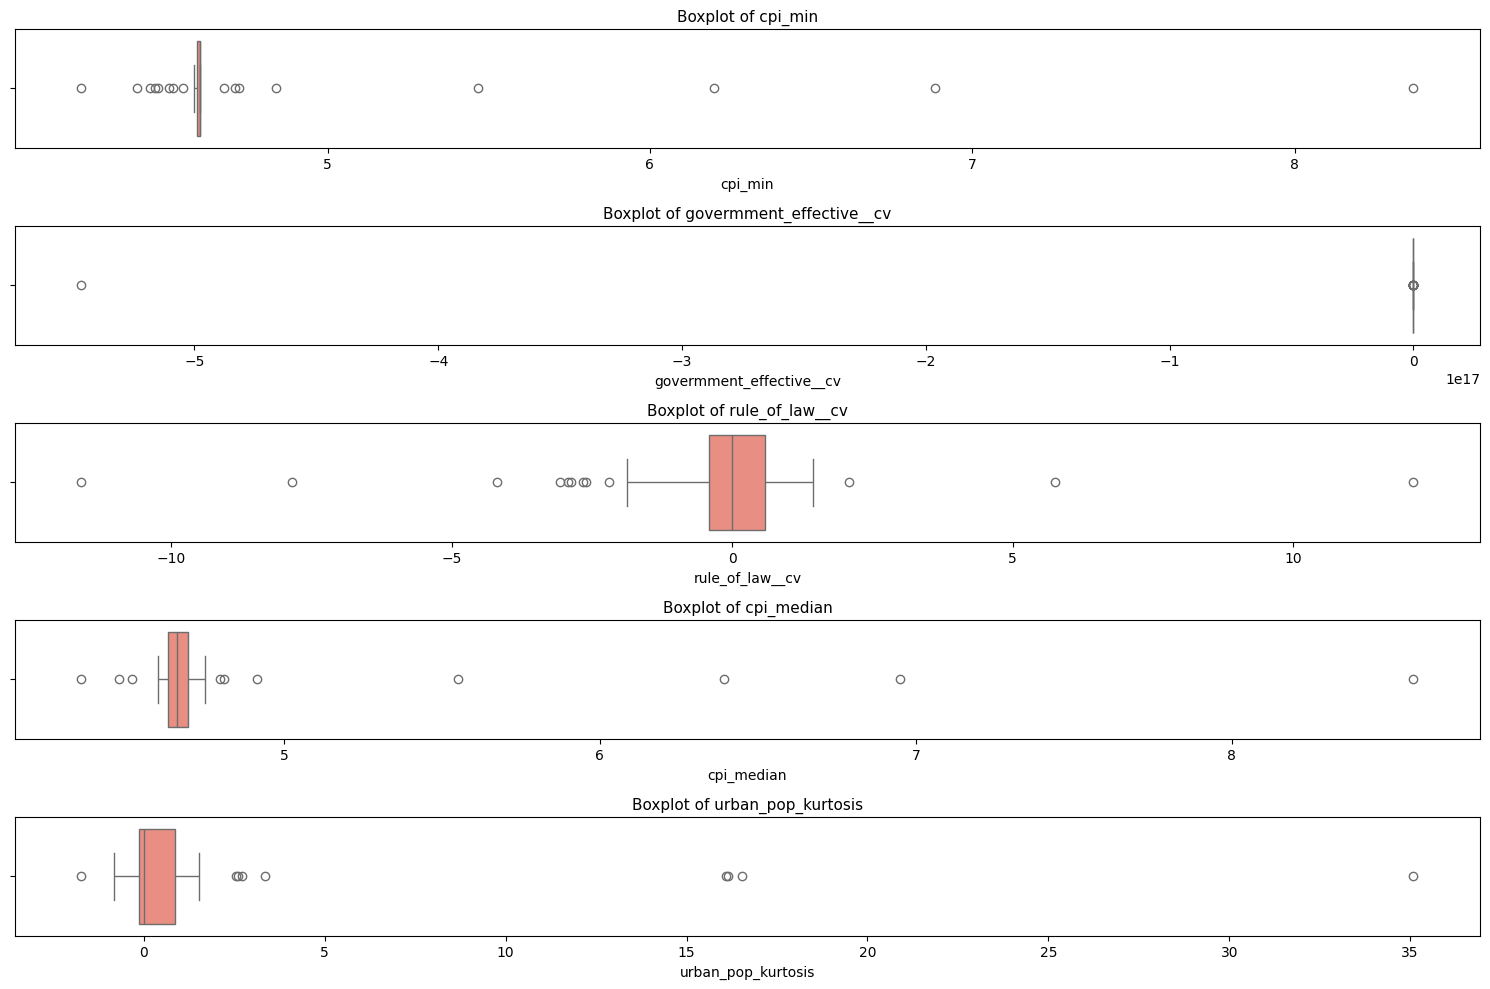

In [21]:
detect_top_outliers(df_final)

In [22]:
from scipy.stats.mstats import winsorize

In [23]:
def winsorize_outlier_columns(df, limits=(0.05, 0.05)):
    """
    Applies winsorization only to numeric columns that contain outliers (based on IQR).

    Parameters:
    - df: pandas DataFrame
    - limits: tuple (lower_limit, upper_limit) for winsorization percentiles

    Returns:
    - df_winsorized: DataFrame with selected columns winsorized
    - outlier_columns: list of columns that were winsorized
    """
    df_winsorized = df.copy()
    numeric_cols = df.select_dtypes(include='number').columns
    outlier_columns = []

    for col in numeric_cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        outliers = df[(df[col] < Q1 - 1.5 * IQR) | (df[col] > Q3 + 1.5 * IQR)]

        if not outliers.empty:
            arr = df[col].values
            arr_winsorized = winsorize(arr, limits=limits).data  # Convert to regular array
            df_winsorized[col] = arr_winsorized
            outlier_columns.append(col)

    return df_winsorized, outlier_columns

In [31]:
df_final_win1, outliers_column1 = winsorize_outlier_columns(df_final)

In [32]:
len(outliers_column1)

122

In [33]:
df_final_win2, outliers_column2 = winsorize_outlier_columns(df_final_win1, limits=(0.07, 0.07))

In [34]:
len(outliers_column2)

48

In [35]:
df_final_win3, outliers_column3 = winsorize_outlier_columns(df_final_win2, limits=(0.08, 0.08))

In [36]:
len(outliers_column3)

25

In [37]:
df_final_win4, outliers_column4 = winsorize_outlier_columns(df_final_win3, limits=(0.09, 0.09))

In [38]:
len(outliers_column4)

18

In [39]:
df_final_win5, outliers_column5 = winsorize_outlier_columns(df_final_win4, limits=(0.10, 0.10))

In [40]:
len(outliers_column5)

18

In [45]:
df_final_win6, outliers_column6 = winsorize_outlier_columns(df_final_win5, limits=(0.11, 0.11))

In [46]:
len(outliers_column6)

9

In [47]:
df_final_win7, outliers_column7 = winsorize_outlier_columns(df_final_win6, limits=(0.12, 0.12))

In [48]:
len(outliers_column7)

9

In [74]:
df_final_win8, outliers_column8 = winsorize_outlier_columns(df_final_win7, limits=(0.13, 0.13))

In [75]:
len(outliers_column8)

8

### Import Clusters

In [108]:
import country_converter as coco

In [109]:
def replace_spaces_in_country_names(df, country_column='Country'):
    """
    Reemplaza espacios por guiones en los nombres de países dentro de la columna 'Country'.

    Parameters:
    - df: DataFrame que contiene la columna de países
    - country_column: nombre de la columna con los países (por defecto 'Country')

    Returns:
    - DataFrame con los nombres modificados
    """
    df[country_column] = df[country_column].astype(str).str.replace(' ', '-', regex=False)
    return df

In [110]:
winner_cluster = pd.read_parquet('../data/clusters/winner_cluster.parquet')

In [111]:
df_final_win8['UNregion'] = coco.convert(names=df_final_win8['Country'], to='UNregion')

In [112]:
winner_cluster

,Country,ISO_A3,cluster,Continent
1,Austria,AUT,1,Europe
2,Belgium,BEL,1,Europe
8,Croatia,HRV,1,Europe
10,Czech Republic,CZE,0,Europe
12,Estonia,EST,1,Europe
13,Finland,FIN,1,Europe
14,France,FRA,0,Europe
15,Germany,DEU,0,Europe
16,Greece,GRC,1,Europe
18,Iceland,ISL,0,Europe


In [113]:
winner_cluster = replace_spaces_in_country_names(winner_cluster)

In [114]:
winner_cluster

,Country,ISO_A3,cluster,Continent
1,Austria,AUT,1,Europe
2,Belgium,BEL,1,Europe
8,Croatia,HRV,1,Europe
10,Czech-Republic,CZE,0,Europe
12,Estonia,EST,1,Europe
13,Finland,FIN,1,Europe
14,France,FRA,0,Europe
15,Germany,DEU,0,Europe
16,Greece,GRC,1,Europe
18,Iceland,ISL,0,Europe


In [115]:
df_final_win8['cluster'] = np.nan

In [116]:
df_final_win8

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_min,labor_force_max,labor_force_last,livestock_prod_mean,livestock_prod_median,livestock_prod_std,...,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend,UNregion,cluster,PC1,PC2
0,Australia,2.679788,2.679994,0.481437,2.619583,2.740840,2.740840,4.528397,4.508659,1.820075,...,0.446512,0.415094,0.307484,-0.441818,0.951482,0.382432,Australia and New Zealand,NaN,1.418995,1.053857
1,Austria,1.736775,1.731656,0.088532,1.717395,1.763017,1.763017,4.614130,4.615121,0.377242,...,0.465116,0.218868,-0.027312,-0.217619,1.793971,0.000000,Western Europe,NaN,-8.298649,-0.037534
2,Belgium,1.825355,1.821318,0.140643,1.791759,1.859418,1.859418,4.636378,4.628887,0.985339,...,0.269767,0.000000,-0.430462,0.984994,0.212296,-0.577027,Western Europe,NaN,-7.244906,0.360187
3,Brazil,4.651376,4.653484,0.793224,4.612046,4.675629,4.673763,4.672829,4.675629,1.646041,...,-1.246512,-1.200000,1.929154,0.630335,-0.767854,-0.586486,South America,NaN,8.950146,0.333562
4,Bulgaria,1.448095,1.451614,0.091234,1.408545,1.477049,1.408545,4.528397,4.508659,1.688591,...,-0.874419,-0.747170,-0.883356,-1.160918,0.275574,-0.232432,Eastern Europe,NaN,-12.903793,0.140713
5,Canada,3.082552,3.073850,0.586940,3.038792,3.141563,3.141563,4.728184,4.749703,2.044840,...,0.660465,0.362264,-0.104998,0.481178,-0.194282,-0.441892,Northern America,NaN,2.977512,1.622282
6,Chile,2.328545,2.318950,0.359796,2.278292,2.394252,2.394252,4.629277,4.634243,1.343487,...,-0.186047,-0.241509,-0.120171,-0.667898,0.533206,-0.298649,South America,NaN,23.928345,-7.500207
7,Colombia,3.263926,3.260977,0.615870,3.217675,3.306520,3.306520,4.634729,4.672829,2.554313,...,-1.023256,-0.845283,-0.857328,0.985186,-0.483123,0.577027,South America,NaN,27.395131,-8.410132
8,Croatia,1.010873,1.007958,0.031453,0.996949,1.029619,1.007958,4.614724,4.620059,1.427140,...,-0.372093,-0.249057,1.929154,1.068808,0.474262,0.929730,Southern Europe,NaN,-17.575046,-1.743324
9,Cyprus,0.524137,0.521766,0.036849,0.494696,0.553885,0.553885,4.742843,4.753590,2.199057,...,-0.139535,-0.226415,-0.298884,-0.116202,-0.767854,-0.343243,Western Asia,NaN,-20.566073,-4.678106


In [124]:
df_final_win8 = replace_spaces_in_country_names(df_final_win8)

In [125]:
def assign_clusters_by_country(source_df, target_df, country_column='Country', cluster_column='cluster'):
    """
    Asigna valores de 'cluster' desde source_df a target_df según coincidencia en 'Country'.

    Parameters:
    - source_df: DataFrame que contiene los valores correctos de 'cluster'
    - target_df: DataFrame al que se le asignarán los valores
    - country_column: nombre de la columna con los países
    - cluster_column: nombre de la columna con los clusters

    Returns:
    - target_df con la columna 'cluster' actualizada
    """
    # Crear diccionario de país → cluster
    cluster_map = source_df.set_index(country_column)[cluster_column].to_dict()

    # Asignar valores al target_df si el país existe en el mapa
    target_df[cluster_column] = target_df[country_column].map(cluster_map)

    return target_df

In [126]:
target_dd = assign_clusters_by_country(winner_cluster, df_final_win8)

In [127]:
target_dd

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_min,labor_force_max,labor_force_last,livestock_prod_mean,livestock_prod_median,livestock_prod_std,...,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend,UNregion,cluster,PC1,PC2
0,Australia,2.679788,2.679994,0.481437,2.619583,2.740840,2.740840,4.528397,4.508659,1.820075,...,0.446512,0.415094,0.307484,-0.441818,0.951482,0.382432,Australia and New Zealand,NaN,1.418995,1.053857
1,Austria,1.736775,1.731656,0.088532,1.717395,1.763017,1.763017,4.614130,4.615121,0.377242,...,0.465116,0.218868,-0.027312,-0.217619,1.793971,0.000000,Western Europe,1.0,-8.298649,-0.037534
2,Belgium,1.825355,1.821318,0.140643,1.791759,1.859418,1.859418,4.636378,4.628887,0.985339,...,0.269767,0.000000,-0.430462,0.984994,0.212296,-0.577027,Western Europe,1.0,-7.244906,0.360187
3,Brazil,4.651376,4.653484,0.793224,4.612046,4.675629,4.673763,4.672829,4.675629,1.646041,...,-1.246512,-1.200000,1.929154,0.630335,-0.767854,-0.586486,South America,NaN,8.950146,0.333562
4,Bulgaria,1.448095,1.451614,0.091234,1.408545,1.477049,1.408545,4.528397,4.508659,1.688591,...,-0.874419,-0.747170,-0.883356,-1.160918,0.275574,-0.232432,Eastern Europe,NaN,-12.903793,0.140713
5,Canada,3.082552,3.073850,0.586940,3.038792,3.141563,3.141563,4.728184,4.749703,2.044840,...,0.660465,0.362264,-0.104998,0.481178,-0.194282,-0.441892,Northern America,NaN,2.977512,1.622282
6,Chile,2.328545,2.318950,0.359796,2.278292,2.394252,2.394252,4.629277,4.634243,1.343487,...,-0.186047,-0.241509,-0.120171,-0.667898,0.533206,-0.298649,South America,NaN,23.928345,-7.500207
7,Colombia,3.263926,3.260977,0.615870,3.217675,3.306520,3.306520,4.634729,4.672829,2.554313,...,-1.023256,-0.845283,-0.857328,0.985186,-0.483123,0.577027,South America,NaN,27.395131,-8.410132
8,Croatia,1.010873,1.007958,0.031453,0.996949,1.029619,1.007958,4.614724,4.620059,1.427140,...,-0.372093,-0.249057,1.929154,1.068808,0.474262,0.929730,Southern Europe,1.0,-17.575046,-1.743324
9,Cyprus,0.524137,0.521766,0.036849,0.494696,0.553885,0.553885,4.742843,4.753590,2.199057,...,-0.139535,-0.226415,-0.298884,-0.116202,-0.767854,-0.343243,Western Asia,NaN,-20.566073,-4.678106


### Apply PCA

In [132]:
df_final_win8 = df_final_win8.drop(['PC1', 'PC2'], axis=1)

In [133]:
from sklearn.decomposition import PCA

In [135]:
pca_input = df_final_win8.select_dtypes(include='number').drop(columns=['cluster'])

In [136]:
pca_2 = PCA(n_components=2)

In [137]:
pca_2_data = pca_2.fit_transform(pca_input)

In [138]:
pca_df = pd.DataFrame(pca_2_data, columns=['PC1', 'PC2'])

In [139]:
pca_df.head()

,PC1,PC2
0,1.418995,1.053857
1,-8.298649,-0.037534
2,-7.244906,0.360187
3,8.950146,0.333562
4,-12.903793,0.140713


In [140]:
pca_df

,PC1,PC2
0,1.418995,1.053857
1,-8.298649,-0.037534
2,-7.244906,0.360187
3,8.950146,0.333562
4,-12.903793,0.140713
5,2.977512,1.622282
6,23.928345,-7.500207
7,27.395131,-8.410132
8,-17.575046,-1.743324
9,-20.566073,-4.678106


### Plot region based

In [141]:
def plot_region_clusters(df, x_col, y_col, region_col='UNregion',
                         country_col='Country', highlight_country='Paraguay'):
    # Extraer coordenadas
    X = df[[x_col, y_col]].values
    regions = df[region_col].values
    countries = df[country_col].values

    # Crear figura
    plt.figure(figsize=(10, 6))

    # Colores y marcadores por región
    unique_regions = sorted(df[region_col].unique())
    colors = ['lightgreen', 'orange', 'lightblue', 'purple', 'gold', 'pink', 'gray', 'brown', 'cyan', 'red']
    markers = ['o', 's', 'v', '^', '<', '>', 'D', 'p', '*', 'h']
    special_marker = 'X'  # marcador especial para Paraguay

    region_color_map = {region: colors[i % len(colors)] for i, region in enumerate(unique_regions)}
    region_marker_map = {region: markers[i % len(markers)] for i, region in enumerate(unique_regions)}

    # Graficar cada región
    for region in unique_regions:
        region_mask = (regions == region)
        region_color = region_color_map[region]
        region_marker = region_marker_map[region]

        # Separar Paraguay del resto
        paraguay_mask = region_mask & (countries == highlight_country)
        others_mask = region_mask & (countries != highlight_country)

        # Graficar otros países de la región
        plt.scatter(X[others_mask, 0], X[others_mask, 1],
                    s=50, c=region_color, marker=region_marker,
                    edgecolor='black', label=f'{region}')

        # Graficar Paraguay con marcador especial
        if paraguay_mask.any():
            plt.scatter(X[paraguay_mask, 0], X[paraguay_mask, 1],
                        s=100, c=region_color, marker=special_marker,
                        edgecolor='black', label=f'{highlight_country} ({region})')

    plt.xlabel(x_col)
    plt.ylabel(y_col)

    # 🧭 Mover la leyenda al costado derecho
    plt.legend(scatterpoints=1, loc='center left', bbox_to_anchor=(1, 0.5))
    plt.grid(True)
    plt.tight_layout()
    plt.title(f'Regional Clustering: {x_col} vs {y_col}')
    plt.show()

In [142]:
target_dd['PC1'] = pca_df['PC1']
target_dd['PC2'] = pca_df['PC2']

In [143]:
target_dd = target_dd[target_dd['Country'] != 'Turkey']

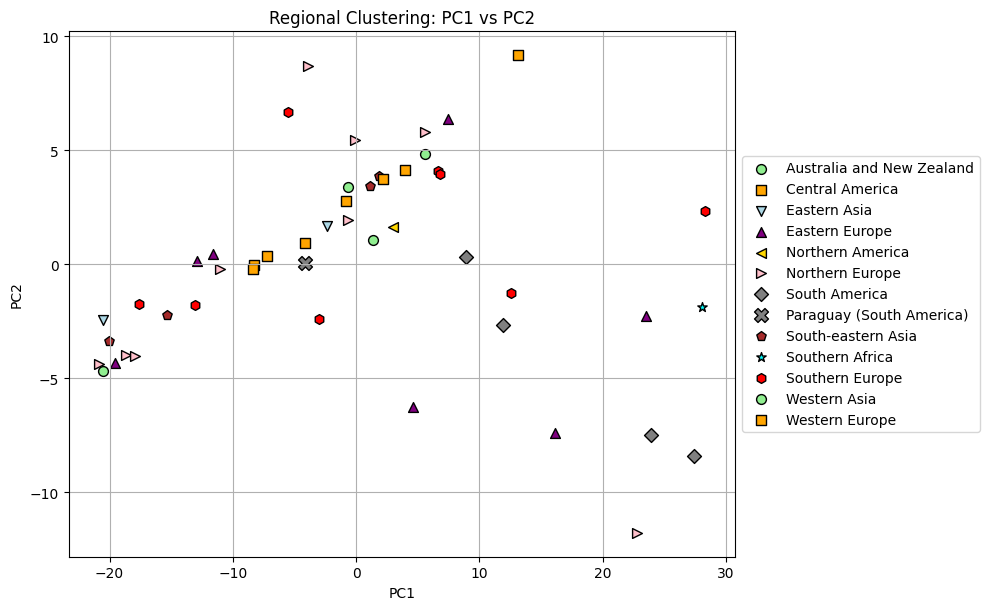

In [144]:
plot_region_clusters(target_dd, 'PC1', 'PC2')

### Plot winner cluster based

In [145]:
def plot_clusters(df, x_col, y_col, cluster_col='cluster', country_col='Country', highlight_country='Paraguay'):
    """
    Plotea un scatter plot 2D coloreando los países según su cluster.
    Los países sin cluster (NaN) se muestran en gris con transparencia.
    """
    plt.figure(figsize=(10, 6))

    # Colores para clusters definidos
    unique_clusters = sorted(df[cluster_col].dropna().unique())
    colors = ['lightgreen', 'orange', 'lightblue', 'purple', 'gold', 'pink', 'brown', 'cyan', 'red', 'olive']
    cluster_color_map = {cluster: colors[i % len(colors)] for i, cluster in enumerate(unique_clusters)}

    # Graficar países con cluster definido
    for cluster in unique_clusters:
        mask = df[cluster_col] == cluster
        highlight_mask = mask & (df[country_col] == highlight_country)
        normal_mask = mask & (df[country_col] != highlight_country)

        # Otros países
        plt.scatter(df.loc[normal_mask, x_col], df.loc[normal_mask, y_col],
                    s=50, c=cluster_color_map[cluster], marker='o',
                    edgecolor='black', label=f'Cluster {int(cluster)}')

        # Paraguay destacado
        if highlight_mask.any():
            plt.scatter(df.loc[highlight_mask, x_col], df.loc[highlight_mask, y_col],
                        s=100, c=cluster_color_map[cluster], marker='X',
                        edgecolor='black', label=f'{highlight_country} (Cluster {int(cluster)})')

    # Graficar países sin cluster
    no_cluster_mask = df[cluster_col].isna()
    if no_cluster_mask.any():
        plt.scatter(df.loc[no_cluster_mask, x_col], df.loc[no_cluster_mask, y_col],
                    s=50, c='gray', alpha=0.5, marker='o',
                    edgecolor='black', label='Sin cluster')

    plt.xlabel(x_col)
    plt.ylabel(y_col)
    plt.legend(scatterpoints=1, loc='center left', bbox_to_anchor=(1, 0.5))
    plt.grid(True)
    plt.tight_layout()
    plt.title(f'Cluster Mapping: {x_col} vs {y_col}')
    plt.show()

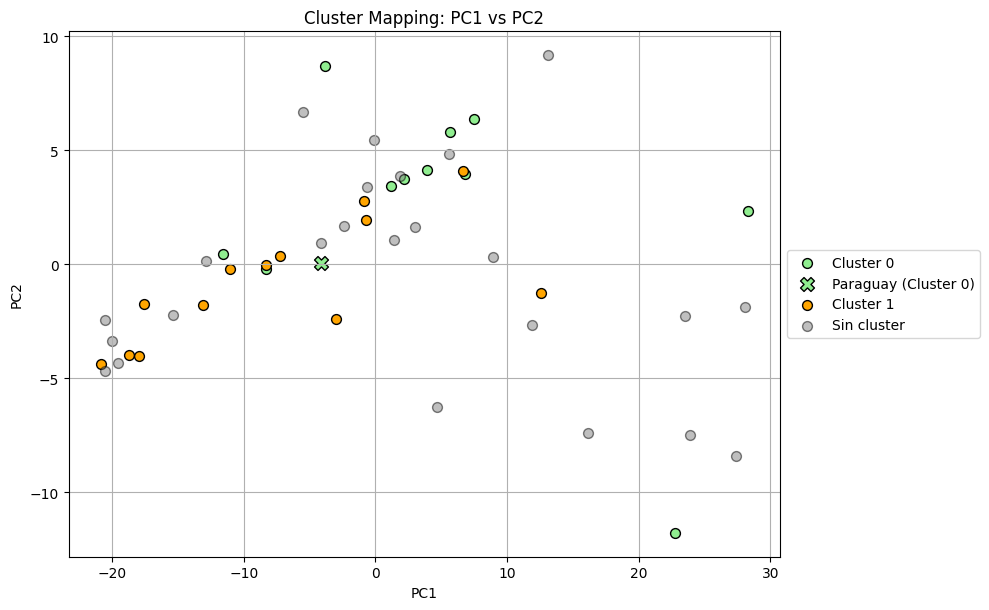

In [146]:
plot_clusters(target_dd, 'PC1', 'PC2')

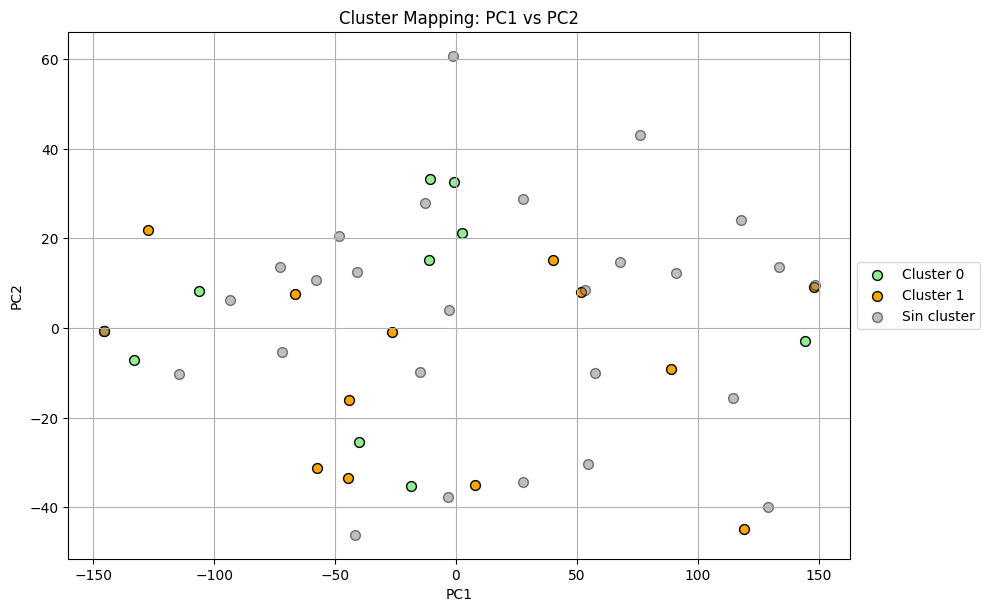

In [38]:
plot_clusters(target_df_hpi, 'PC1', 'PC2')